# Unassigned evidence
This is for large deletions, insertions, translocations and other kinds of evil. These are things Breseq didn't fully process ([this page](https://barricklab.org/twiki/pub/Lab/ToolsBacterialGenomeResequencing/documentation/tutorial_clones.html) suggests to do edits manually).

These do not appear in the VCF files, so we'll extract them from the index.html files.

The goal here is to make sure we're not missing something important.

In [5]:
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import os

from tqdm import tqdm

In [6]:
def get_text(row, tag = 'td', space = ' '):
    '''Get the text content of a BS table.'''
    return [h.text.replace('\xa0', space) for h in row.find_all(tag)]

In [3]:
unassigned_junctions['p1'] = unassigned_junctions.pos1.apply(lambda x: int(x.replace('=', '')))
unassigned_junctions['p2'] = unassigned_junctions.pos2.apply(lambda x: int(x.replace('=', '')))

NameError: name 'unassigned_junctions' is not defined

In [4]:
unassigned_junctions.to_csv('../../../datasets/genomics/02_structural_variation/results/unassigned_junctions.tsv', sep = '\t', index = False)
unassigned_missing_coverage.to_csv('../../../datasets/genomics/02_structural_variation/results/unassigned_missing_coverage.tsv', sep = '\t', index = False)

NameError: name 'unassigned_junctions' is not defined

# Read TSV

In [7]:
unassigned_junctions = pd.read_csv('../../../datasets/genomics/02_structural_variation/results/unassigned_junctions.tsv', sep = '\t')
unassigned_missing_coverage = pd.read_csv('../../../datasets/genomics/02_structural_variation/results/unassigned_missing_coverage.tsv', sep = '\t')

# Missing coverage

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
unassigned_missing_coverage['pos'] = unassigned_missing_coverage.start.apply(lambda x: x.split('-')[0]).astype(int)

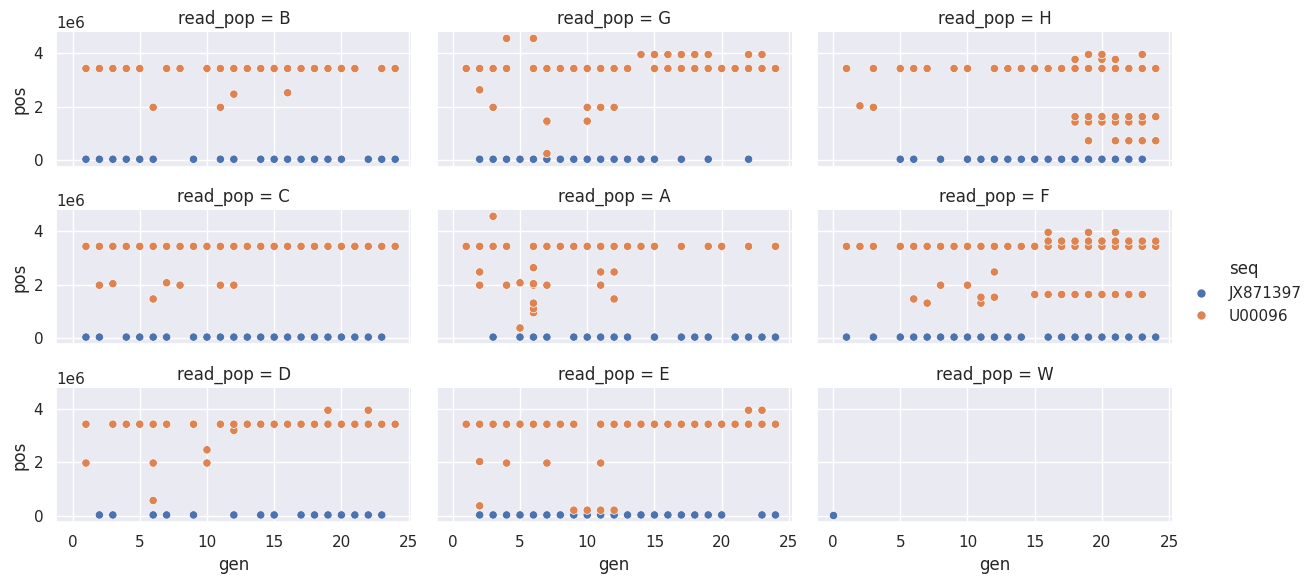

In [10]:
sns.set_theme(rc={'figure.figsize':(1,8.27)})
sns.relplot(kind = 'scatter',
            data = unassigned_missing_coverage,#[unassigned_missing_coverage.seq == 'U00096'], 
            x = 'gen', y = 'pos', col = 'read_pop', hue = 'seq', col_wrap = 3, height = 2, aspect=2, marker = 'o')

**What is the apparently-universal deletion around 3,423,700 ?**

This is an artifact of very repetitive sequences in tRNAs / rRNA.

<div>
<img src="missing_coverage_plot.png" width="500"/>
</div>

The other missing regions might be legit, though.

# New junctions

In [14]:
unassigned_junctions['f'] = np.where(unassigned_junctions.freq == 'NA', 0, unassigned_junctions.freq)
unassigned_junctions['p1'] = unassigned_junctions.pos1.apply(lambda x: int(x.replace('=', '')))
unassigned_junctions['p2'] = unassigned_junctions.pos2.apply(lambda x: int(x.replace('=', '')))
unassigned_junctions['bp'] = unassigned_junctions.p2 - unassigned_junctions.p1

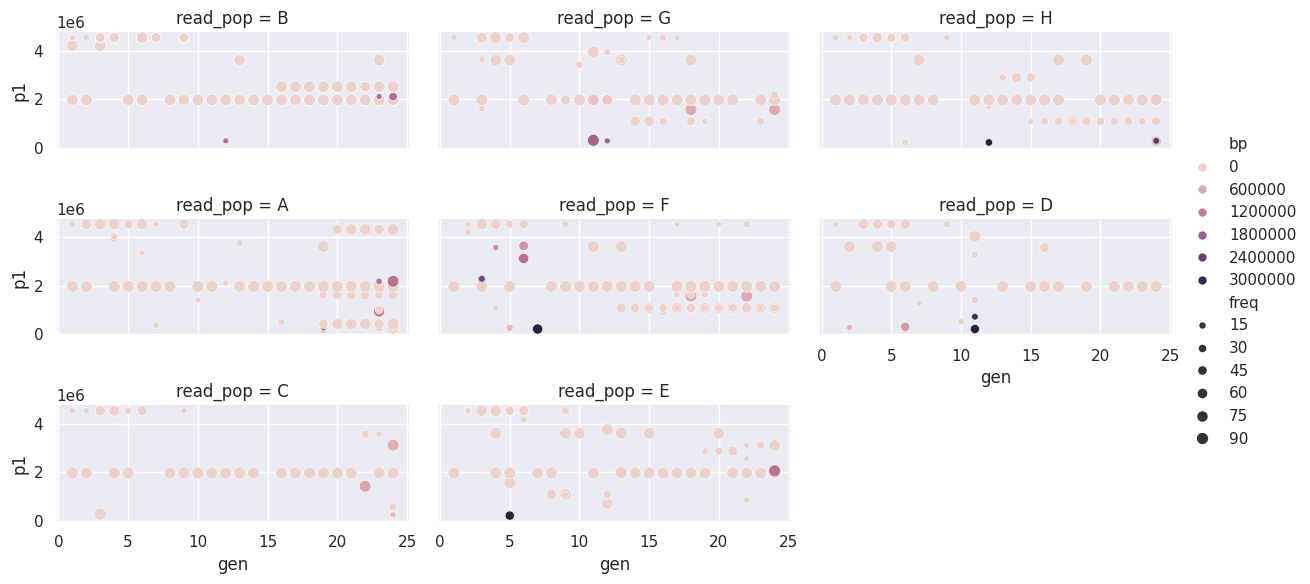

In [15]:
# Find junctions not present in WT
unassigned_junctions['in_wt'] = unassigned_junctions.groupby(['p1', 'p2']).read_pop.transform(lambda x: (x == 'W').any())

sns.relplot(kind = 'scatter', 
            data = unassigned_junctions[
                (unassigned_junctions.f > 10) &
                ~(unassigned_junctions.in_wt) &
                (unassigned_junctions.seq1 == 'U00096') & (unassigned_junctions.seq2 == 'U00096')
            ], 
            hue = 'bp', x = 'gen', y = 'p1', col = 'read_pop', size = 'freq', col_wrap = 3, height = 2, aspect=2)

**What are the inversions around 4542682 that appear gradually then disappear in the early stage?**

This is the Fim switch. See the dedicated notebooks.
